# 05 - Layer 2: thematic categorisation

The first layer gives the sentiment of a sentence. The second layer gives its topic and the specific problem:

```
sentence --> [layer 1] sentiment (B)                   -> negative / neutral / positive
         --> [2/a] aspect classifier (HRAST, BERT)     -> topic, e.g. bathroom
         --> [2/b] subtopics (embedding + clustering)  -> problem, e.g. "no hot water"
```

| # | Step | Measurement |
|---|---|---|
| 1 | 2/a training on HRAST | F1 per aspect on the HRAST test set, compared with the keyword list |
| 2 | 2/a on the Booking sentences | agreement with the keyword list |
| 3 | 2/b subtopics per aspect | NPMI coherence, diversity, stability (ARI) |
| 4 | Complaint map | lift by segment |
| 5 | Manual check | precision per topic |

Requirements: model (B) in `results/models/approach_b_hrast`, the HRAST csv in `data/raw/hrast/`, and `sentence-transformers` and `umap-learn`. The unit of analysis is the clause, taken separately from the praise and complaint fields. Training 2/a takes 10–15 minutes on a GPU.

## 1. Environment and data

In [1]:
# The notebooks run from notebooks/, so the project root is added to the path.
import sys, os
sys.path.insert(0, os.path.abspath(".."))

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import set_seed
from src.config import CFG, PATHS, SENTIMENT_COLORS, INK, APPROACHES, apply_plot_style
from src import data_loading as dl
from src import preprocessing as pp
from src import evaluation as ev
from src import descriptives as ds
from src import aspects as asp
from src import aspect_model as am
from src import topic_modeling as tm
from src import pipeline

set_seed()
PATHS.ensure()
apply_plot_style()
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 170)

# Analysis units: the praise and the complaint field are split into clauses separately (at full stops,
# semicolons, "but / however / although"), so the two never merge into one "sentence". In the praise
# field comma enumerations are split too (CFG.split_praise_lists). The (B) model also runs on every
# unit (about 5–10 min, chunked, resumable).
from src import bert_labelling as bl
meta = ds.prepare_star_rating(dl.read_frame(pipeline.LABELLED))
units = pp.build_field_units(meta)
scorer_b = bl.TransformerScorer(str(PATHS.models / "approach_b_hrast"))
sent = bl.predict_units(units, "", "B", cache_name="B_field_units", scorer=scorer_b)

meta_cols = ["review_id", "score", "label_final", "accommodation_type", "accommodation_country",
             "guest_type", "accommodation_star_rating"]
sent = sent.merge(meta[[c for c in meta_cols if c in meta.columns]], on="review_id", how="left")
dl.write_frame(sent, PATHS.labels / "field_units_B")
print(f"{len(sent):,} units from {sent['review_id'].nunique():,} reviews")

# Field polarity × (B) label: agreement of the model with the field chosen by the guest.
display(pd.crosstab(sent["field_polarity"], sent["B_label"], normalize="index").round(3))

10:34:37 | INFO    | src.preprocessing | Field units: 1100650 from 203079 reviews | by field: {'positive': 827008, 'negative': 273642}
10:34:58 | INFO    | src.bert_labelling | Loading model: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\models\approach_b_hrast (device: cuda, fp16: True)


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

10:35:00 | INFO    | src.bert_labelling | Model type: 3class | labels: ['negative', 'neutral', 'positive']


1,100,650 units from 203,079 reviews


B_label,negative,neutral,positive
field_polarity,,,
negative,0.740,0.079,0.181
positive,0.067,0.049,0.884


## 2. 2/a - Aspect classifier on HRAST

Multi-label BERT with one sigmoid output per aspect. Rare aspects get a larger loss weight (`pos_weight`), the decision thresholds are tuned per aspect on the validation set, and the final evaluation, including the keyword baseline, uses the test set.

In [2]:
hrast_raw = dl.load_hrast_raw()
asp_data, ASPECTS = am.prepare_hrast_aspects(hrast_raw)
counts = asp_data[ASPECTS].sum().sort_values(ascending=False).to_frame("sentences")
counts["share"] = (counts["sentences"] / len(asp_data)).round(4)
display(counts); ev.save_table(counts, "05_hrast_aspect_counts")

10:35:03 | INFO    | src.data_loading | HRAST loaded: hrast.csv — 23113 rows, columns: ['id', 'review', 'Unnamed: 2', 'positive', 'negative', 'neutral', 'Clean', 'Comfort', 'Facilities/Amenities', 'Location', 'Restaurant (dinner)', 'Staff', 'View (Balcony)', 'Breakfast', 'Room', 'Pool', 'Beach', 'Bathroom/Shower (toilet)', 'Bar', 'Bed', 'Parking', 'Noise', 'Reception-checkin', 'Lift', 'Value for money', 'Wi-Fi', 'Generic', 'Aspect']
10:35:03 | INFO    | src.aspect_model | HRAST aspect data: 23105 sentences, 21 aspects | without aspect: 0.0%


,sentences,share
room,5004,0.2166
location,4727,0.2046
staff,3800,0.1645
cleanliness,2926,0.1266
facilities,2923,0.1265
comfort,2561,0.1108
breakfast,2539,0.1099
bathroom,2344,0.1014
generic,1973,0.0854
noise,1604,0.0694


10:35:03 | INFO    | src.evaluation | Table saved: 05_hrast_aspect_counts.csv


WindowsPath('C:/Users/seszt/Documents/BCE/7_felev/Szakdolgozat/THESIS/CODE/results/tables/05_hrast_aspect_counts.csv')

Aspect model already trained — loading the saved test results.


,precision,recall,f1,support
room,0.7927,0.7906,0.7917,769
location,0.9348,0.9556,0.9451,675
staff,0.9193,0.9597,0.9391,546
cleanliness,0.9417,0.9417,0.9417,446
facilities,0.8479,0.8064,0.8266,470
comfort,0.8282,0.8258,0.8270,356
breakfast,0.9280,0.9704,0.9488,372
bathroom,0.9520,0.9242,0.9379,343
generic,0.7085,0.7864,0.7454,309
noise,0.9466,0.9323,0.9394,266


,support,keyword_precision,keyword_recall,keyword_f1,model_precision,model_recall,model_f1,f1_gain
aspect,,,,,,,,
room,769,0.5673,0.8986,0.6955,0.7927,0.7906,0.7917,0.0961
location,675,0.9282,0.9007,0.9143,0.9348,0.9556,0.9451,0.0308
staff,546,0.9022,0.8443,0.8723,0.9193,0.9597,0.9391,0.0668
facilities,470,0.5340,0.3511,0.4236,0.8479,0.8064,0.8266,0.4030
cleanliness,446,0.9332,0.7825,0.8512,0.9417,0.9417,0.9417,0.0905
breakfast,372,0.8589,0.9489,0.9017,0.9280,0.9704,0.9488,0.0471
bathroom,343,0.8963,0.9067,0.9014,0.9520,0.9242,0.9379,0.0364
noise,266,0.9755,0.7481,0.8468,0.9466,0.9323,0.9394,0.0926
value_for_money,136,0.6788,0.6838,0.6813,0.6894,0.8162,0.7475,0.0662


10:35:04 | INFO    | src.evaluation | Figure saved: 05_aspect_keyword_vs_model.png


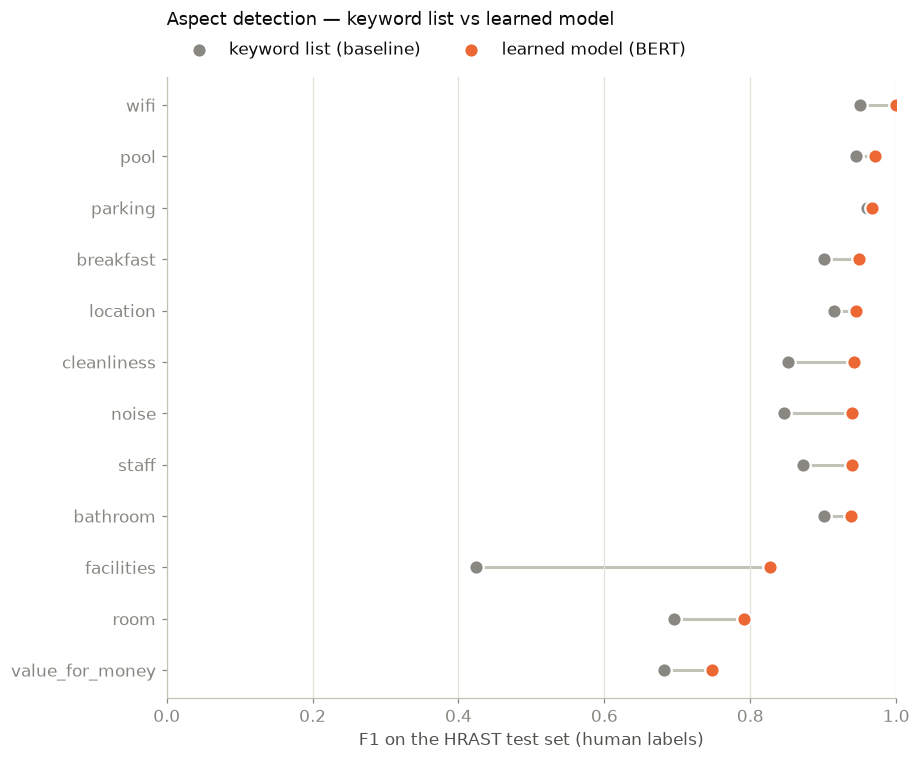

Mean F1 on the shared aspects — keyword: 0.829 | model: 0.913


In [3]:
# If the model already exists it is not retrained (the saved test results are loaded).
if not (am.DEFAULT_MODEL_DIR / "thresholds.json").exists():
    result = am.train_aspect_model(asp_data, ASPECTS)
    report, comparison = result["test_report"], result["keyword_comparison"]
    ev.save_table(report, "05_aspect_model_test_report")
    ev.save_table(comparison, "05_aspect_keyword_vs_model")
else:
    print("Aspect model already trained — loading the saved test results.")
    report = pd.read_csv(PATHS.tables / "05_aspect_model_test_report.csv", index_col=0)
    comparison = pd.read_csv(PATHS.tables / "05_aspect_keyword_vs_model.csv", index_col=0)

display(report)
display(comparison)
am.plot_keyword_vs_model(comparison, save_as="05_aspect_keyword_vs_model"); plt.show()
print(f"Mean F1 on the shared aspects — keyword: {comparison['keyword_f1'].mean():.3f} | "
      f"model: {comparison['model_f1'].mean():.3f}")

## 3. Applying 2/a to the Booking sentences

Chunked, resumable run as in the labelling. There is no human label here, so the result is the agreement with the keyword list, not accuracy.

In [4]:
sent_asp = am.predict_aspects(sent, cache_name="aspects_field_units")
dl.write_frame(sent_asp, PATHS.labels / "field_units_aspects")
ASPECT_NAMES = am.aspect_names_in(sent_asp)

share = sent_asp[[f"asp_{a}" for a in ASPECT_NAMES]].mean().sort_values(ascending=False)
share.index = share.index.str.replace("asp_", "", regex=False)
display(share.round(4).to_frame("share of sentences"))
print(f"Sentences without any aspect: {(sent_asp['n_aspects'] == 0).mean():.1%}")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

10:35:09 | INFO    | src.aspect_model | Aspects predicted for 1100650 sentences | without aspect: 4.1%


,share of sentences
location,0.2064
generic,0.1895
staff,0.1603
room,0.1425
facilities,0.0985
comfort,0.0921
breakfast,0.0921
cleanliness,0.0854
bathroom,0.0451
bed,0.0446


Sentences without any aspect: 4.1%


,mentions,mention_share,negative,neutral,positive,neg_lift,pos_lift
aspect,,,,,,,
lift,5971,0.0054,0.7503,0.0628,0.1869,3.2001,0.2637
bathroom,49626,0.0451,0.5162,0.0641,0.4197,2.2018,0.5921
wifi,6948,0.0063,0.5105,0.0535,0.4360,2.1773,0.6150
noise,37444,0.0340,0.4959,0.0283,0.4759,2.1149,0.6713
facilities,108410,0.0985,0.3781,0.0786,0.5433,1.6126,0.7665
reception,34296,0.0312,0.3407,0.0585,0.6008,1.4533,0.8475
value_for_money,37771,0.0343,0.3202,0.0731,0.6067,1.3658,0.8559
parking,17674,0.0161,0.3182,0.0598,0.6220,1.3569,0.8775
bed,49121,0.0446,0.2783,0.0400,0.6817,1.1868,0.9617


10:35:11 | INFO    | src.evaluation | Table saved: 05_aspect_sentiment_model.csv
10:35:12 | INFO    | src.evaluation | Figure saved: 05_aspect_sentiment_model.png


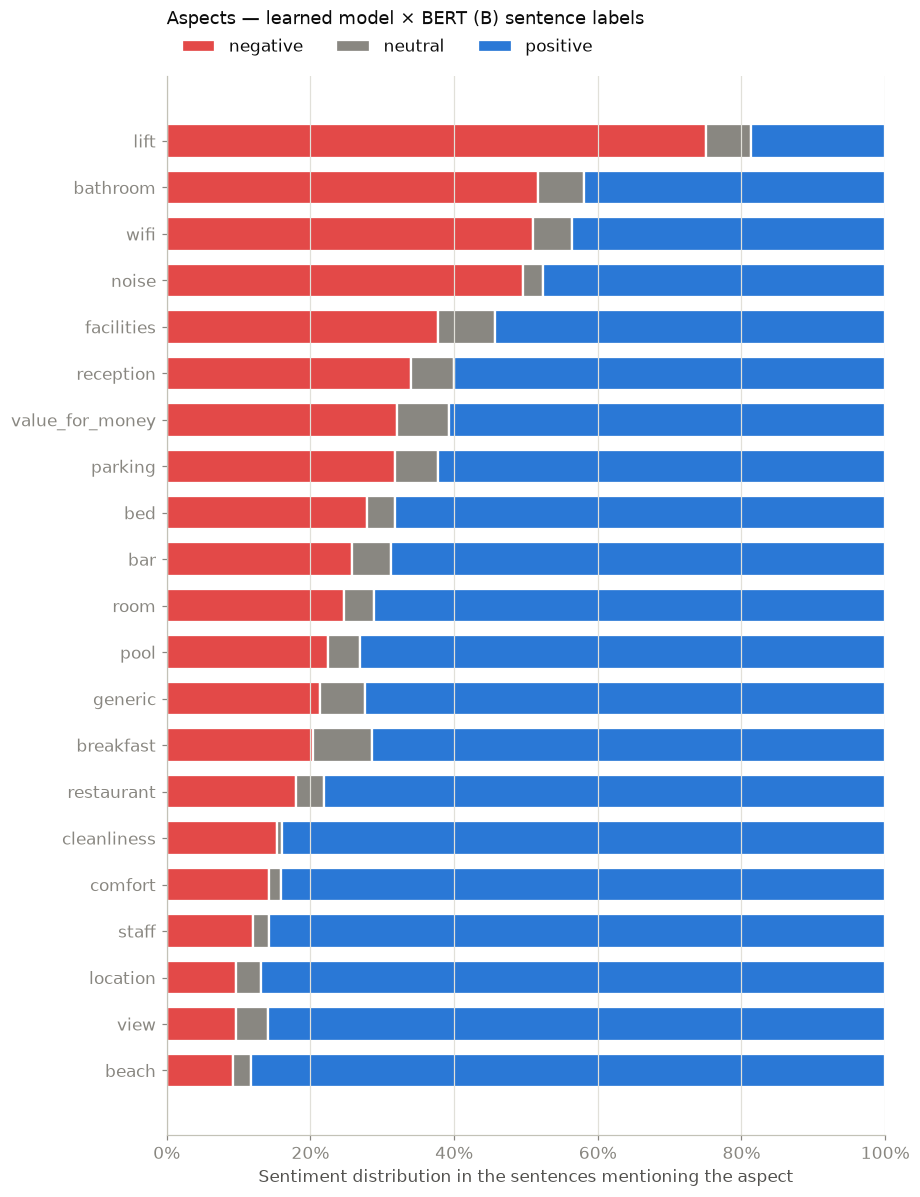

,share_model,share_keyword,agreement,cohen_kappa
aspect,,,,
location,0.2068,0.1498,0.9266,0.7510
staff,0.1615,0.1032,0.9300,0.6973
room,0.1419,0.1861,0.8873,0.5903
facilities,0.0965,0.0566,0.9046,0.3288
breakfast,0.0910,0.0935,0.9673,0.8049
cleanliness,0.0838,0.0759,0.9869,0.9109
bathroom,0.0453,0.0438,0.9874,0.8520
noise,0.0352,0.0283,0.9911,0.8547
value_for_money,0.0349,0.0305,0.9852,0.7669


10:35:14 | INFO    | src.evaluation | Table saved: 05_aspect_keyword_agreement_booking.csv


WindowsPath('C:/Users/seszt/Documents/BCE/7_felev/Szakdolgozat/THESIS/CODE/results/tables/05_aspect_keyword_agreement_booking.csv')

In [5]:
# Aspect × sentiment with the learned aspects (cf. notebook 04: keyword version).
aspect_sent = asp.aspect_sentiment_table(sent_asp, label_col="B_label", aspects=ASPECT_NAMES,
                                         prefix="asp_", min_count=100)
display(aspect_sent); ev.save_table(aspect_sent, "05_aspect_sentiment_model")
asp.plot_aspect_sentiment(aspect_sent, "Aspects — learned model × BERT (B) sentence labels",
                          save_as="05_aspect_sentiment_model"); plt.show()

agreement = am.keyword_agreement(sent_asp.sample(min(50_000, len(sent_asp)), random_state=CFG.random_seed))
display(agreement); ev.save_table(agreement, "05_aspect_keyword_agreement_booking")

## 4. 2/b - Subtopics per aspect

A separate topic model per aspect on the sentences of the selected sentiment (negative by default): Sentence-BERT embedding, UMAP, HDBSCAN and c-TF-IDF. `SENTIMENT = "positive"` produces the praise subtopics; the sentiment is part of the output file names.

In [6]:
SENTIMENT = "positive"
# Version of the subtopic run (CFG.topic_version): part of every output name below, so a new
# parameter set does not overwrite earlier tables, figures and the manual check.
TAG = f"{SENTIMENT}_{CFG.topic_version}"
# Double filter: the guest wrote it into the complaint field and the (B) model also reads it as
# negative (this drops "nothing, all perfect" type units written into the complaint field).
subset = sent_asp[(sent_asp["field_polarity"] == SENTIMENT) & (sent_asp["B_label"] == SENTIMENT)
                  & (sent_asp["n_aspects"] > 0)].reset_index(drop=True)
print(f"{len(subset):,} {SENTIMENT} units with at least one aspect")

embeddings = tm.embed_sentences(subset["sentence"], cache_name=f"emb_{SENTIMENT}_units")

# Remove non-complaint units ("nothing", "no complaints", "all was perfect", "not the hotel's
# fault"). The embedding is made before filtering, so the cache stays valid; rows are selected from
# both afterwards. Applied on the negative side only.
if SENTIMENT == "negative":
    junk = pp.non_complaint_mask(subset["sentence"]).to_numpy()
    removed = subset.loc[junk, "sentence"].str.lower().str.strip(" .!").value_counts()
    print(f"Non-complaint units removed: {junk.sum():,} ({junk.mean():.1%})")
    display(removed.head(15).to_frame("count"))
    ev.save_table(removed.head(200).to_frame("count"), f"05_{TAG}_removed_non_complaints")
    subset, embeddings = subset.loc[~junk].reset_index(drop=True), embeddings[~junk]
print(f"{len(subset):,} units | embeddings: {embeddings.shape}")

714,792 positive units with at least one aspect


10:35:16 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/modules.json "HTTP/1.1 307 Temporary Redirect"
10:35:16 | WARNING | huggingface_hub.utils._http | Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.
10:35:16 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/sentence-transformers/all-MiniLM-L6-v2/1110a243fdf4706b3f48f1d95db1a4f5529b4d41/modules.json?%2Fsentence-transformers%2Fall-MiniLM-L6-v2%2Fresolve%2Fmain%2Fmodules.json=&etag=%22952a9b81c0bfd99800fabf352f69c7ccd46c5e43%22 "HTTP/1.1 200 OK"
10:35:16 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/config_sentence_transformers.json "HTTP/1.1 307 Temporary Redirect"
10:35:16 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/sentence-transform

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

10:35:18 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/processor_config.json "HTTP/1.1 404 Not Found"
10:35:18 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/preprocessor_config.json "HTTP/1.1 404 Not Found"
10:35:18 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/video_preprocessor_config.json "HTTP/1.1 404 Not Found"
10:35:18 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/preprocessor_config.json "HTTP/1.1 404 Not Found"
10:35:19 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/tokenizer_config.json "HTTP/1.1 307 Temporary Redirect"
10:35:19 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/sentence-transformers/all-Mini

714,792 units | embeddings: (714792, 384)


c:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
10:36:23 | INFO    | src.topic_modeling | Topics: 31 | noise 30.5% -> 5.9% | NPMI -0.042 | diversity 0.787


,value
n_sentences,30000.0000
n_topics,31.0000
n_topics_before_merge,31.0000
n_merges,0.0000
min_cluster_size,300.0000
giant_cluster_retries,0.0000
noise_share_before,0.3052
noise_share_after,0.0591
mean_coherence_npmi,-0.0421
topic_diversity,0.7871


,topic,size,share,label,top_terms,coherence_npmi,examples,merged_from
0,0,2268,0.075600,breakfast / breakfast good / good breakfast,"breakfast, breakfast good, good breakfast, good, delicious, great breakfast, breakfast great, breakfast excellent, g...",-0.083200,Breakfast was very nice || breakfast was very nice || Breakfast was very nice,
1,1,1926,0.064200,station / walk / close,"station, walk, close, city, train, town, centre, train station, walking, bus",0.285815,Good location next to the metro and train station (10 min walk) || Excellent location with a 10 minute walk into the...,
2,2,2048,0.068267,staff / friendly / helpful,"staff, friendly, helpful, staff friendly, friendly staff, friendly helpful, helpful staff, staff helpful, desk, kind",0.150919,the staff was so friendly and helpful || The staff was so friendly and helpful || staff very friendly,
3,3,1522,0.050733,recommend / located / hotels,"recommend, located, hotels, hostel, location, motel, beautiful, great, best, nice",-0.211546,The hotel is in a great location || The hotel has a great location || The hotel is wonderfully situated,
4,4,1211,0.040367,restaurants / restaurant / shops,"restaurants, restaurant, shops, close, bar, nearby, food, shopping, supermarket, bars",0.034237,nearby shopping and restaurants || Restaurants and shop nearby || Near restaurants and shops,
5,5,1089,0.036300,host / reception / hosts,"host, reception, hosts, welcome, helpful, friendly, reception staff, welcoming, family, feel",-0.085299,the host was always very pleasant and helpful || Our hosts were very welcoming || The host was friendly and helpful,
6,6,1020,0.034000,quiet / accommodation / noise,"quiet, accommodation, noise, peaceful, cozy, atmosphere, quiet location, relaxing, night, comfortable",-0.188672,"Very quiet place || Perfect location, quiet || Perfect location, quiet",
7,7,1048,0.034933,experience / needed / perfect,"experience, needed, perfect, great, nothing, thank, service, view, loved, nice",-0.242210,Everything was great || Everything was great || Everything was great,
8,8,752,0.025067,pool / swimming / swimming pool,"pool, swimming, swimming pool, spa, gym, pool area, pools, nice, area, nice pool",0.055232,Pool was beautiful and relaxing || pool is very nice || The pool is nice,
9,9,1065,0.035500,room / spacious / room spacious,"room, spacious, room spacious, room comfortable, comfortable, rooms, room nice, view, room great, suite",-0.146302,The room was nice and spacious || The room was very spacious || the room was very spacious,


10:36:23 | INFO    | src.evaluation | Table saved: 05_positive_full2_topics_overview.csv
10:36:24 | INFO    | src.evaluation | Figure saved: 05_positive_full2_topics_overview.png


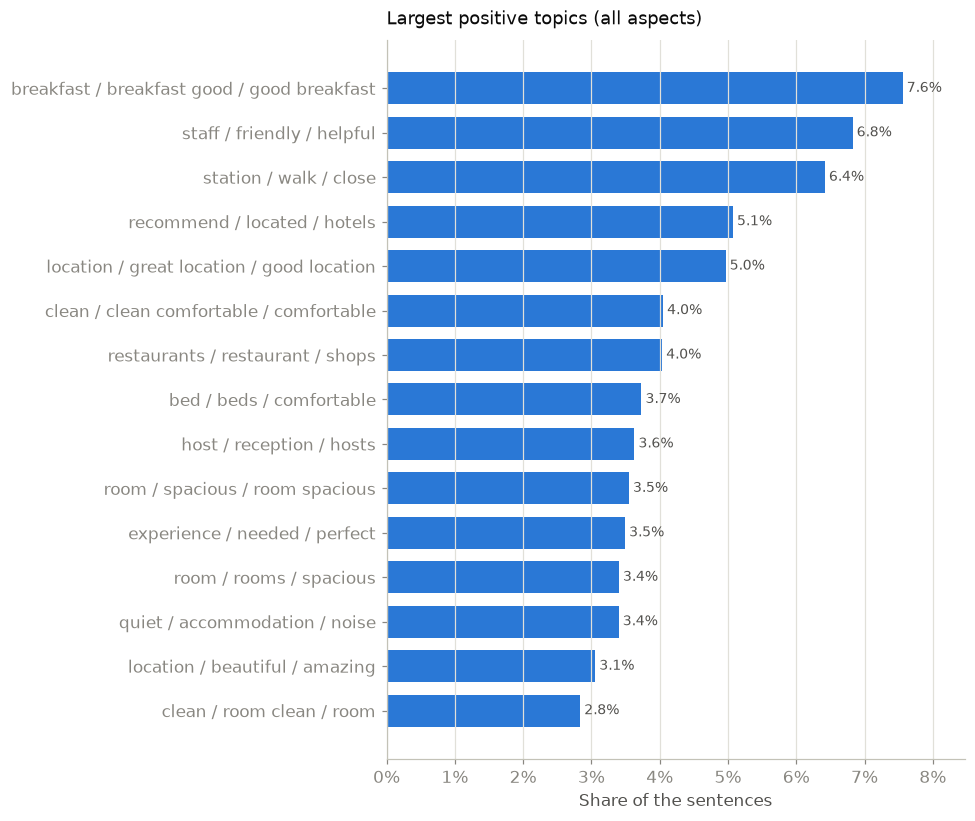

In [7]:
# Overview topic model on a sample of these sentences, independent of the aspect.
rng = np.random.default_rng(CFG.random_seed)
overview_rows = np.sort(rng.choice(len(subset), size=min(30_000, len(subset)), replace=False))
overview = tm.fit_topics(subset["sentence"].iloc[overview_rows], embeddings[overview_rows])
display(pd.Series(overview.metrics).to_frame("value"))
display(overview.topic_info.head(20))
ev.save_table(overview.topic_info, f"05_{TAG}_topics_overview")
tm.plot_topic_sizes(overview.topic_info, f"Largest {SENTIMENT} topics (all aspects)", sentiment=SENTIMENT,
                    save_as=f"05_{TAG}_topics_overview"); plt.show()

### Granularity sweep

A single global cluster size did not suit every aspect: at 1% there were 19–21 small, overlapping subtopics, at 3% the bathroom aspect collapsed to 2 subtopics. The final setting therefore uses fine clustering followed by merging of the most similar subtopics (average linkage) until at most `CFG.subtopic_max_topics` remain and no two topics are more similar than `CFG.subtopic_merge_similarity`. A merged subtopic is limited to `CFG.subtopic_max_topic_share` (35%) of the aspect, which prevents catch-all topics. The table compares the options on the three largest aspects (`none` = no merging). UMAP runs once per aspect (1–2 minutes); `RUN_SWEEP = False` skips the sweep.

In [8]:
RUN_SWEEP = True
if RUN_SWEEP:
    flag_counts = {a: int(subset[f"asp_{a}"].sum()) for a in ASPECT_NAMES if a not in ("generic",)}
    sweep_aspects = sorted(flag_counts, key=flag_counts.get, reverse=True)[:3]
    sweeps = []
    for aspect in sweep_aspects:
        rows = np.where(subset[f"asp_{aspect}"].to_numpy() == 1)[0]
        rows = np.sort(np.random.default_rng(CFG.random_seed).choice(
            rows, size=min(len(rows), CFG.topic_sample_per_aspect), replace=False))
        sweeps.append(tm.granularity_sweep(subset["sentence"].iloc[rows], embeddings[rows])
                        .reset_index().assign(aspect=aspect))
    sweep = pd.concat(sweeps, ignore_index=True).set_index(["aspect", "min_cluster_share", "max_topics"])
    display(sweep); ev.save_table(sweep, f"05_{TAG}_granularity_sweep")
print("Chosen subtopic settings:", tm.subtopic_params())

c:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
10:36:31 | INFO    | src.topic_modeling | Topics: 27 | noise 22.7% -> 3.2% | NPMI -0.267 | diversity 0.778
10:36:31 | INFO    | src.topic_modeling | Topics: 12 | noise 22.7% -> 3.2% | NPMI -0.089 | diversity 0.783
10:36:32 | INFO    | src.topic_modeling | Topics: 10 | noise 22.7% -> 3.2% | NPMI -0.084 | diversity 0.790
10:36:32 | INFO    | src.topic_modeling | Topics: 8 | noise 22.7% -> 3.2% | NPMI -0.093 | diversity 0.838
10:36:32 | INFO    | src.topic_modeling | Topics: 6 | noise 22.7% -> 3.2% | NPMI -0.072 | diversity 0.817
10:36:32 | INFO    | src.topic_modeling | Topics: 14 | noise 21.7% -> 3.2% | NPMI -0.139 | diversity 0.729
10:36:33 | INFO    | src.topic_modeling | Topics: 12 | noise 21.7% -> 3.2% | NPMI -0.090 | diversity 0.725
10:36:33 | INFO    | src.topic_modeling |

min_cluster_size  n_topics_before_merge  n_topics  noise_share_before  mean_coherence_npmi  topic_diversity  largest_topic_share
aspect   min_cluster_share max_topics                                                                                                                                  
location 0.01              none                      50                     27        27              0.2272              -0.2668           0.7778               0.1048
                           12                        50                     27        12              0.2272              -0.0890           0.7833               0.2592
                           10                        50                     27        10              0.2272              -0.0842           0.7900               0.2592
                           8                         50                     27         8              0.2272              -0.0933           0.8375               0.2592
                           6                         50                     27         6              0.2272              -0.0717           0.8167               0.3366
         0.02              none                     100                     14        14              0.2168              -0.1391           0.7286               0.1338
                           12                       100                     14        12              0.2168              -0.0902           0.7250               0.1400
                           10                       100                     14        10              0.2168              -0.0672           0.7500               0.3060
                           8                        100                     14         8              0.2168              -0.0829           0.7500               0.3060
                           6                        100                     14         6              0.2168              -0.0595           0.8000               0.3352
staff    0.01              none                      50                     32        32              0.2046              -0.3096           0.6467               0.1118
                           12                        50                     32        12              0.2046              -0.1969           0.7417               0.3330
                           10                        50                     32        10              0.2046              -0.1850           0.7200               0.3330
                           8                         50                     32         8              0.2046              -0.1693           0.7500               0.3330
                           6                         50                     32         6              0.2046              -0.1149           0.7667               0.3330
         0.02              none                     100                     15        15              0.2496              -0.1781           0.7000               0.1602
                           12                       100                     15        12              0.2496              -0.0961           0.6750               0.2214
                           10                       100                     15        10              0.2496              -0.1216           0.6900               0.3206
                           8                        100                     15         8              0.2496              -0.0864           0.7250               0.3206
                           6                        100                     15         6              0.2496              -0.1049           0.8167               0.3206
room     0.01              none                      50                     32        32              0.2560              -0.3147           0.6906               0.0894
                           12                        50                     32        12              0.2560              -0.1920           0.7500               0.2496
       

10:36:52 | INFO    | src.evaluation | Table saved: 05_positive_full2_granularity_sweep.csv


Chosen subtopic settings: {'min_cluster_share': 0.02, 'max_topics': 10, 'merge_similarity': 0.9, 'max_topic_share': 0.35, 'max_initial_share': 0.5}


In [9]:
topic_table, assignments, topic_summary = tm.fit_subtopics_per_aspect(subset, embeddings, ASPECT_NAMES)
display(topic_summary)
ev.save_table(topic_summary, f"05_{TAG}_subtopic_quality")
MAIN_ASPECTS = (topic_summary[topic_summary["n_topics"] > 0]
                .sort_values("n_sentences", ascending=False).index.tolist())
print("Main aspects:", MAIN_ASPECTS)
ev.save_table(topic_table, f"05_{TAG}_subtopics")

10:36:52 | INFO    | src.topic_modeling | room             107550 sentences (model fitted on 5000)
c:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
10:36:59 | INFO    | src.topic_modeling | Topics: 10 | noise 28.2% -> 1.8% | NPMI -0.171 | diversity 0.770
10:37:00 | INFO    | src.topic_modeling | location         191437 sentences (model fitted on 5000)
c:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
10:37:07 | INFO    | src.topic_modeling | Topics: 10 | noise 26.2% -> 3.1% | NPMI -0.032 | diversity 0.800
10:37:07 | INFO    | src.topic_modeling | staff            145059 sentences (model fitted on 5000)
c:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\.ve

,n_sentences,n_topics_before_merge,n_topics,min_cluster_size,giant_cluster_retries,noise_share_before,noise_share_after,mean_coherence_npmi,topic_diversity
aspect,,,,,,,,,
room,5000,14,10,100,0,0.2822,0.0184,-0.1709,0.77
location,5000,14,10,100,0,0.2622,0.0308,-0.0316,0.80
staff,5000,16,10,100,0,0.1630,0.0434,-0.1789,0.72
cleanliness,5000,15,10,100,0,0.1172,0.0024,-0.1412,0.76
facilities,5000,18,10,100,0,0.1790,0.0526,-0.1126,0.88
comfort,5000,13,10,100,0,0.1136,0.0056,-0.1686,0.62
breakfast,5000,31,10,50,1,0.2694,0.0048,-0.1566,0.74
bathroom,5000,16,10,100,0,0.2700,0.0044,-0.1457,0.73
noise,5000,15,10,100,0,0.3564,0.0094,-0.1498,0.80


10:39:18 | INFO    | src.evaluation | Table saved: 05_positive_full2_subtopic_quality.csv
10:39:18 | INFO    | src.evaluation | Table saved: 05_positive_full2_subtopics.csv


Main aspects: ['room', 'location', 'staff', 'cleanliness', 'facilities', 'comfort', 'breakfast', 'bathroom', 'noise', 'bed', 'reception', 'value_for_money', 'view', 'parking', 'pool', 'bar', 'restaurant', 'beach', 'wifi', 'lift']


WindowsPath('C:/Users/seszt/Documents/BCE/7_felev/Szakdolgozat/THESIS/CODE/results/tables/05_positive_full2_subtopics.csv')

### Naming the subtopics

After the manual check every cluster received an English name (`src/topic_names.py`). Near-duplicate clusters share a name, so figures and complaint maps combine them. The automatic c-TF-IDF label is kept as `auto_label` and works as a fingerprint: if a rerun produces different clusters, the cell raises an error. Without names for the current version, the renaming is skipped.

10:39:24 | INFO    | src.evaluation | Table saved: 05_positive_full2_subtopics.csv
10:39:24 | INFO    | src.evaluation | Table saved: 05_positive_full2_named_subtopics.csv
10:39:24 | INFO    | src.evaluation | Table saved: 05_positive_full2_subtopic_quality.csv


191 clusters -> 167 named subtopics


aspect,room,location,staff,cleanliness,facilities,comfort,breakfast,bathroom,noise,bed,reception,value_for_money,view,parking,pool,bar,restaurant,lift,wifi,beach
n_topics,10,10,10,10,10,10,10,10,10,10,9,10,10,10,10,10,10,2,10,10
n_named_subtopics,9,9,9,10,10,8,8,8,9,8,7,9,9,9,10,10,9,1,7,8


10:39:28 | INFO    | src.evaluation | Figure saved: 05_positive_full2_subtopics_by_aspect.png


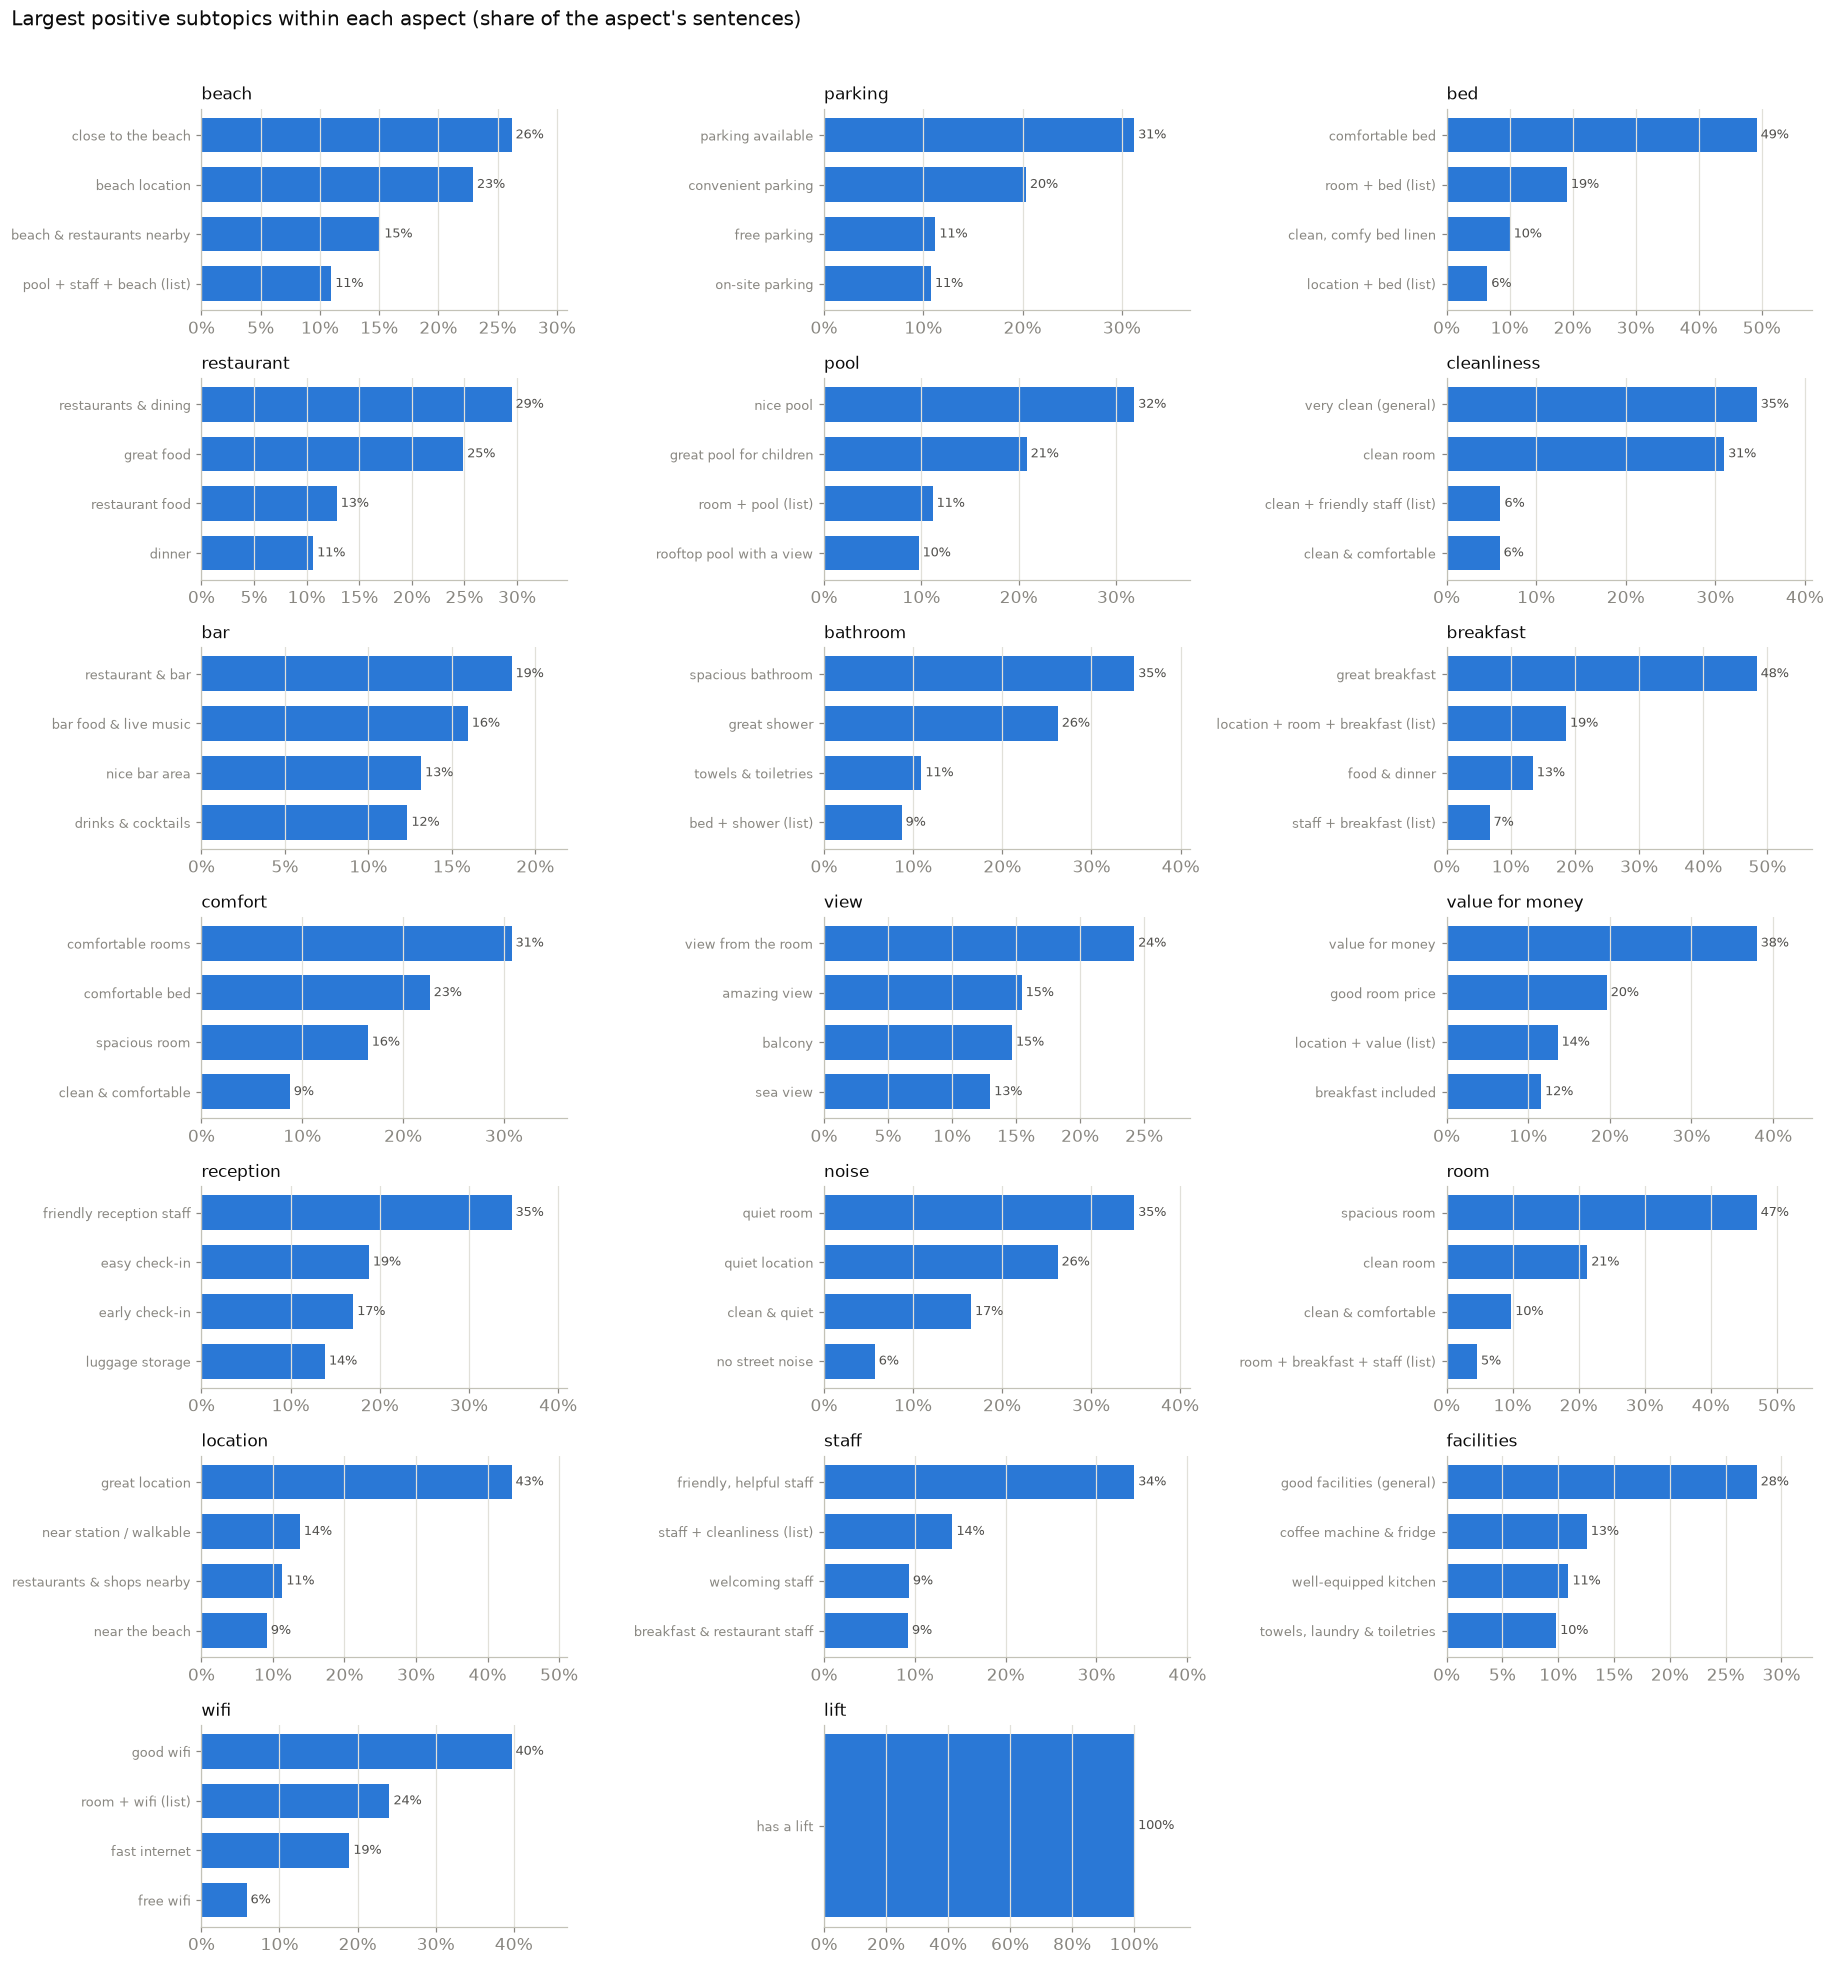

In [10]:
from src import topic_names

if topic_names.TOPIC_VERSION == CFG.topic_version:
    TOPIC_NAMES = topic_names.get_topic_names(SENTIMENT, topic_table)  # fingerprint-checked
    topic_table, assignments = tm.rename_topics(topic_table, assignments, TOPIC_NAMES)
    ev.save_table(topic_table, f"05_{TAG}_subtopics")
    named = tm.collapse_named_topics(topic_table)
    ev.save_table(named, f"05_{TAG}_named_subtopics")
    n_named = named.groupby("aspect", sort=False).size().rename("n_named_subtopics")
    topic_summary = topic_summary.join(n_named)
    ev.save_table(topic_summary, f"05_{TAG}_subtopic_quality")
    print(f"{len(topic_table)} clusters -> {len(named)} named subtopics")
    display(topic_summary[["n_topics", "n_named_subtopics"]].T)
else:
    print(f"No names for topic_version={CFG.topic_version!r} (names are for {topic_names.TOPIC_VERSION!r}) — "
          "automatic labels are kept.")

dl.write_frame(assignments.assign(review_id=subset["review_id"].iloc[assignments["row"]].to_numpy(),
                                  sentence=subset["sentence"].iloc[assignments["row"]].to_numpy()),
               PATHS.labels / f"subtopic_assignments_{TAG}")
tm.plot_aspect_subtopics(topic_table, top_k=4, sentiment=SENTIMENT,
                         save_as=f"05_{TAG}_subtopics_by_aspect"); plt.show()

In [11]:
for aspect in MAIN_ASPECTS[:4]:
    print(f"\n=== {aspect} ===")
    for _, r in topic_table[topic_table["aspect"] == aspect].head(6).iterrows():
        auto = f"  <- {r['auto_label']}" if "auto_label" in r else ""
        print(f"  [{r['topic']}] {r['label']}  ({r['share_within_aspect']:.0%}, NPMI {r['coherence_npmi']:.2f}){auto}")
        if r["merged_from"]:
            print(f"       merged from: {r['merged_from'][:150]}")
        print(f"       e.g. {r['examples'].split(' || ')[0][:150]}")


=== room ===
  [0] spacious room  (27%, NPMI -0.05)  <- room / spacious / rooms
       merged from: room / rooms / spacious + bathroom / shower / room bathroom
       e.g. spacious and nice rooms
  [1] clean room  (21%, NPMI -0.29)  <- clean / room clean / room
       merged from: clean / clean room / rooms + room clean / clean / room
       e.g. Rooms very clean
  [2] spacious room  (20%, NPMI -0.10)  <- room / spacious / room spacious
       merged from: room / view / room spacious + room / decorated / room great + room comfortable / comfortable / room
       e.g. The room was very spacious
  [3] clean & comfortable  (10%, NPMI -0.32)  <- comfortable / clean comfortable / clean
       e.g. Clean and comfortable
  [4] room + breakfast + staff (list)  (5%, NPMI 0.13)  <- breakfast / staff / friendly
       e.g. Pleasant staff comfortable room good breakfast
  [5] cosy room, pleasant temperature  (4%, NPMI -0.52)  <- cozy / air / warm
       e.g. Warm and comfortable room

=== location

### Stability

The same model with three random seeds on the three largest aspects. An adjusted Rand index (ARI) above 0.5 indicates that the topics are not a product of chance.

In [12]:
stability_rows = []
for aspect in MAIN_ASPECTS[:3]:
    rows = np.where(subset[f"asp_{aspect}"].to_numpy() == 1)[0]
    rows = np.sort(np.random.default_rng(CFG.random_seed).choice(
        rows, size=min(len(rows), CFG.topic_sample_per_aspect), replace=False))
    table = tm.topic_stability(subset["sentence"].iloc[rows], embeddings[rows], **tm.subtopic_params())
    stability_rows.append({"aspect": aspect, "mean_pairwise_ari": table.attrs["mean_pairwise_ari"],
                           "n_topics_per_seed": table["n_topics"].tolist()})
stability = pd.DataFrame(stability_rows).set_index("aspect").round(3)
display(stability); ev.save_table(stability, f"05_{TAG}_subtopic_stability")

c:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
10:39:36 | INFO    | src.topic_modeling | Topics: 10 | noise 28.2% -> 1.8% | NPMI -0.171 | diversity 0.770
c:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
10:39:43 | INFO    | src.topic_modeling | Topics: 10 | noise 24.5% -> 1.4% | NPMI -0.148 | diversity 0.760
c:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
10:39:50 | INFO    | src.topic_modeling | Topics: 10 | noise 25.2% -> 1.4% | NPMI -0.146 | diversity 0.760
10:39:50 | INFO    | src.topic_modeling | S

,mean_pairwise_ari,n_topics_per_seed
aspect,,
room,0.826,"[10, 10, 10]"
location,0.653,"[10, 10, 10]"
staff,0.652,"[10, 10, 10]"


10:40:31 | INFO    | src.evaluation | Table saved: 05_positive_full2_subtopic_stability.csv


WindowsPath('C:/Users/seszt/Documents/BCE/7_felev/Szakdolgozat/THESIS/CODE/results/tables/05_positive_full2_subtopic_stability.csv')

## 5. Complaint map

Share of the subtopics of an aspect by segment, as lift: above 1 the subtopic is more common in the segment than on average. Each cell has a two-proportion z-test (segment vs. rest) with Benjamini–Hochberg correction. `*` marks cells that are significant and differ by at least 20% (|lift − 1| ≥ 0.2); other cells are faded. A subtopic more common than average gets the sentiment colour (complaint = red, praise = blue), a rarer one grey.

10:40:31 | INFO    | src.evaluation | Table saved: 05_positive_full2_map_room_by_accommodation_type.csv


,segment,subtopic,lift,count,segment_n,q,significant,notable
13,Apartment,spacious apartment,6.591,2256,9118,0.0,True,True
5,ApartHotel,spacious apartment,3.998,715,4764,0.0,True,True
39,Hostel,"cosy room, pleasant temperature",1.976,190,2913,0.0,True,True
10,Apartment,clean & comfortable,1.603,1558,9118,0.0,True,True
14,Apartment,balcony / terrace,1.523,470,9118,0.0,True,True
38,Hostel,balcony / terrace,1.450,143,2913,0.0,True,True
62,Resort,balcony / terrace,1.426,162,3356,0.0,True,True
31,Guest house,"cosy room, pleasant temperature",1.414,383,8208,0.0,True,True


10:40:32 | INFO    | src.evaluation | Figure saved: 05_positive_full2_map_room_by_accommodation_type.png


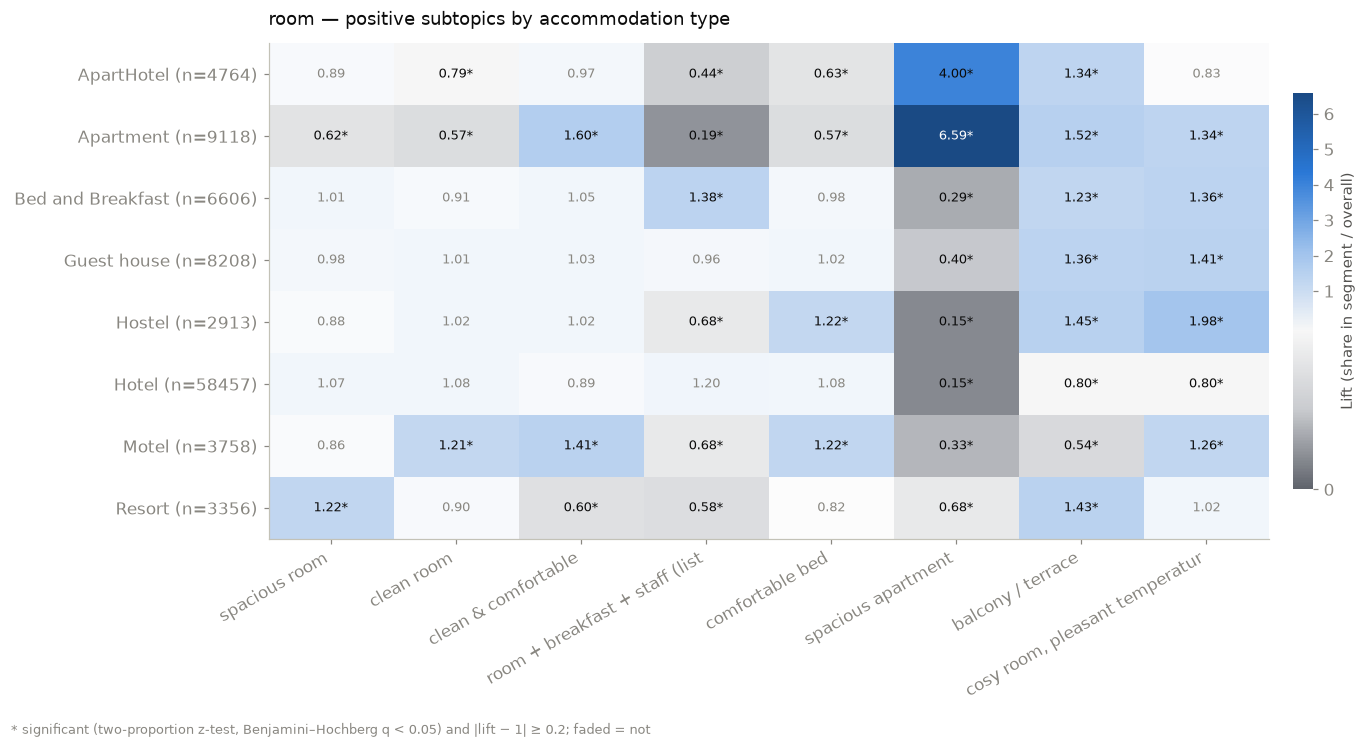

10:40:33 | INFO    | src.evaluation | Table saved: 05_positive_full2_map_room_by_accommodation_country.csv


,segment,subtopic,lift,count,segment_n,q,significant,notable
37,Spain,spacious apartment,2.727,417,4124,0.0,True,True
23,Greece,balcony / terrace,2.465,241,3096,0.0,True,True
21,Greece,spacious apartment,2.343,269,3096,0.0,True,True
39,Spain,balcony / terrace,2.081,271,4124,0.0,True,True
31,Italy,balcony / terrace,1.955,473,7661,0.0,True,True
29,Italy,spacious apartment,1.609,457,7661,0.0,True,True
51,United Kingdom,room + breakfast + staff (list),1.377,1706,20949,0.0,True,True
5,Australia,spacious apartment,1.326,276,5612,0.0,True,True


10:40:34 | INFO    | src.evaluation | Figure saved: 05_positive_full2_map_room_by_accommodation_country.png


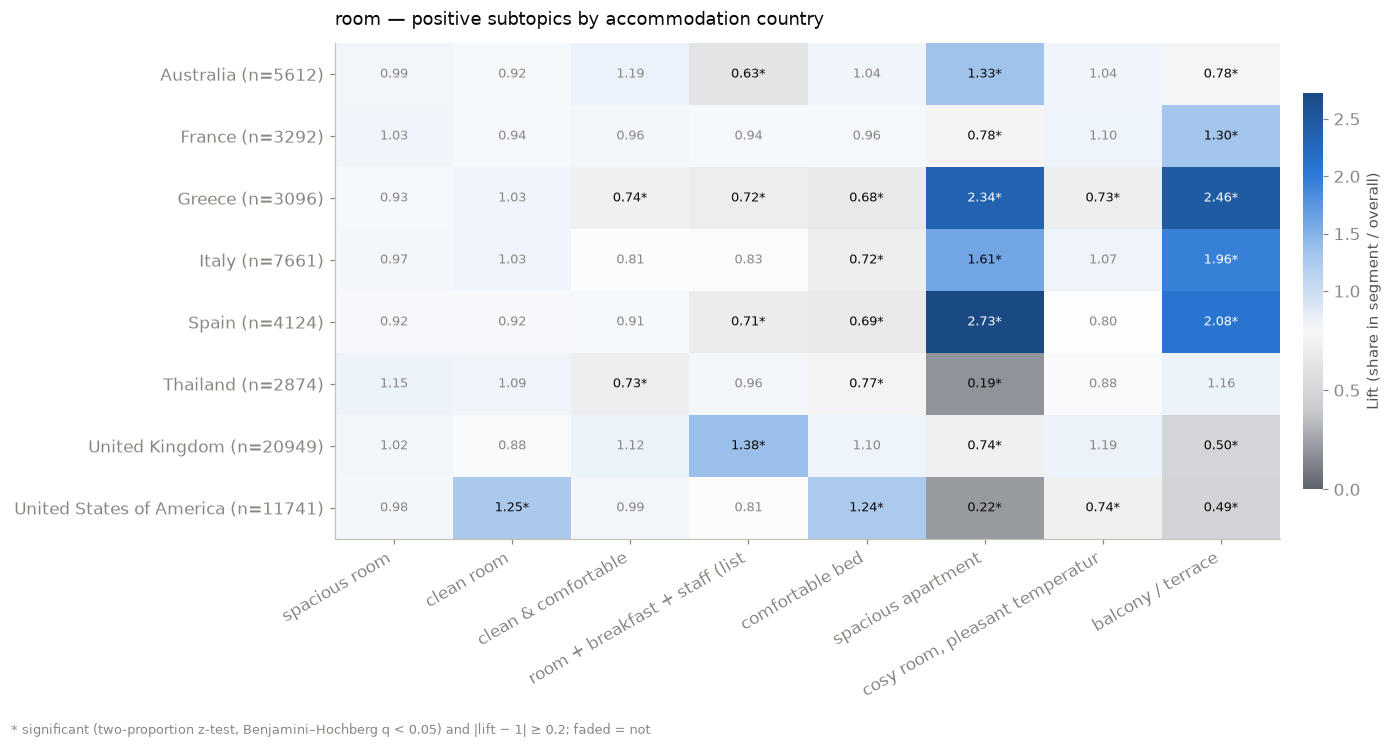

10:40:35 | INFO    | src.evaluation | Table saved: 05_positive_full2_map_location_by_accommodation_type.csv


,segment,subtopic,lift,count,segment_n,q,significant,notable
60,Resort,near the beach,4.282,2068,5680,0.0,True,True
22,Bed and Breakfast,quiet location,1.723,495,9058,0.0,True,True
4,ApartHotel,near the beach,1.588,1174,8693,0.0,True,True
52,Motel,near the beach,1.495,650,5114,0.0,True,True
50,Motel,restaurants & shops nearby,1.394,816,5114,0.0,True,True
45,Hotel,near the airport,1.388,6301,96592,0.0,True,True
2,ApartHotel,restaurants & shops nearby,1.307,1301,8693,0.0,True,True
30,Guest house,quiet location,1.306,549,13255,0.0,True,True


10:40:36 | INFO    | src.evaluation | Figure saved: 05_positive_full2_map_location_by_accommodation_type.png


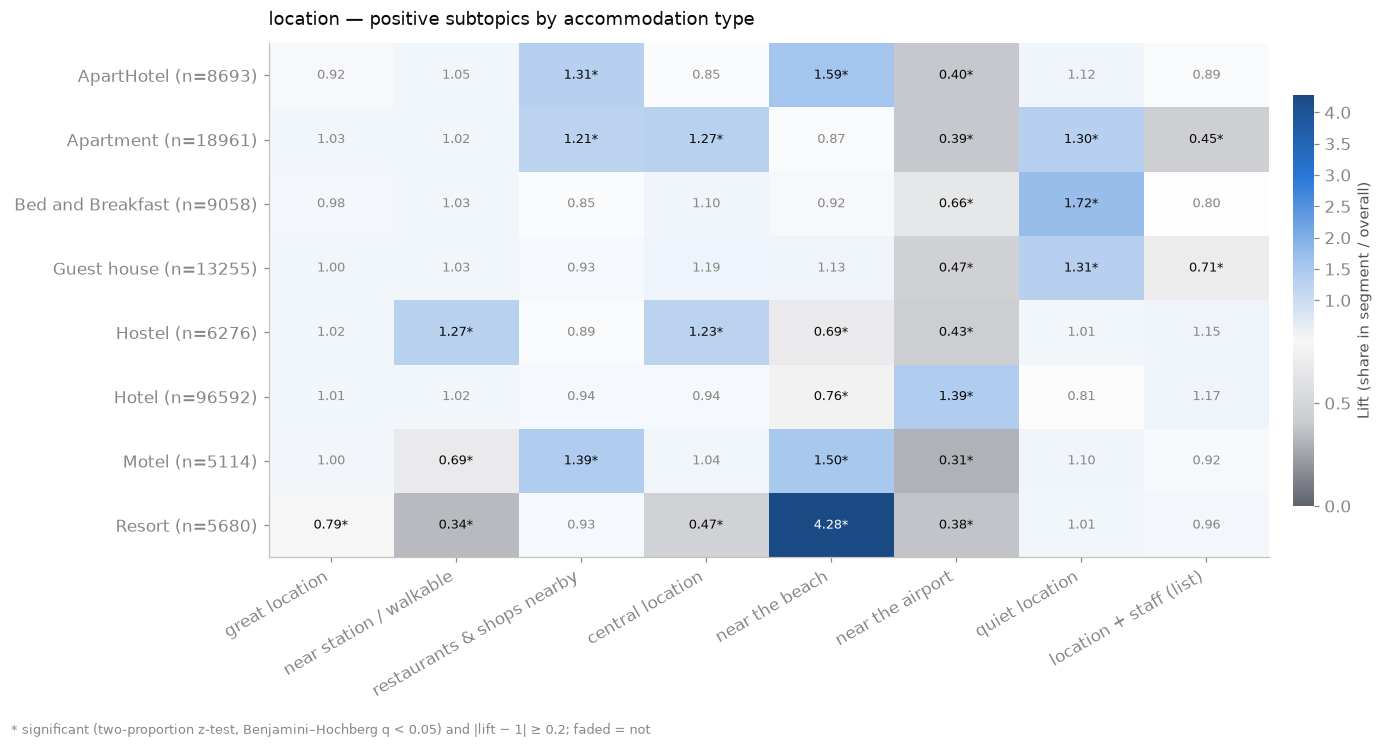

10:40:36 | INFO    | src.evaluation | Table saved: 05_positive_full2_map_location_by_accommodation_country.csv


,segment,subtopic,lift,count,segment_n,q,significant,notable
20,Greece,near the beach,2.637,1284,6491,0.0,True,True
33,Japan,near station / walkable,1.966,1640,5511,0.0,True,True
4,Australia,near the beach,1.560,985,8415,0.0,True,True
53,United Kingdom,near the airport,1.546,1891,27953,0.0,True,True
44,Spain,near the beach,1.496,981,8743,0.0,True,True
34,Japan,restaurants & shops nearby,1.363,852,5511,0.0,True,True
2,Australia,restaurants & shops nearby,1.360,1298,8415,0.0,True,True
25,Italy,near station / walkable,1.349,3206,15702,0.0,True,True


10:40:37 | INFO    | src.evaluation | Figure saved: 05_positive_full2_map_location_by_accommodation_country.png


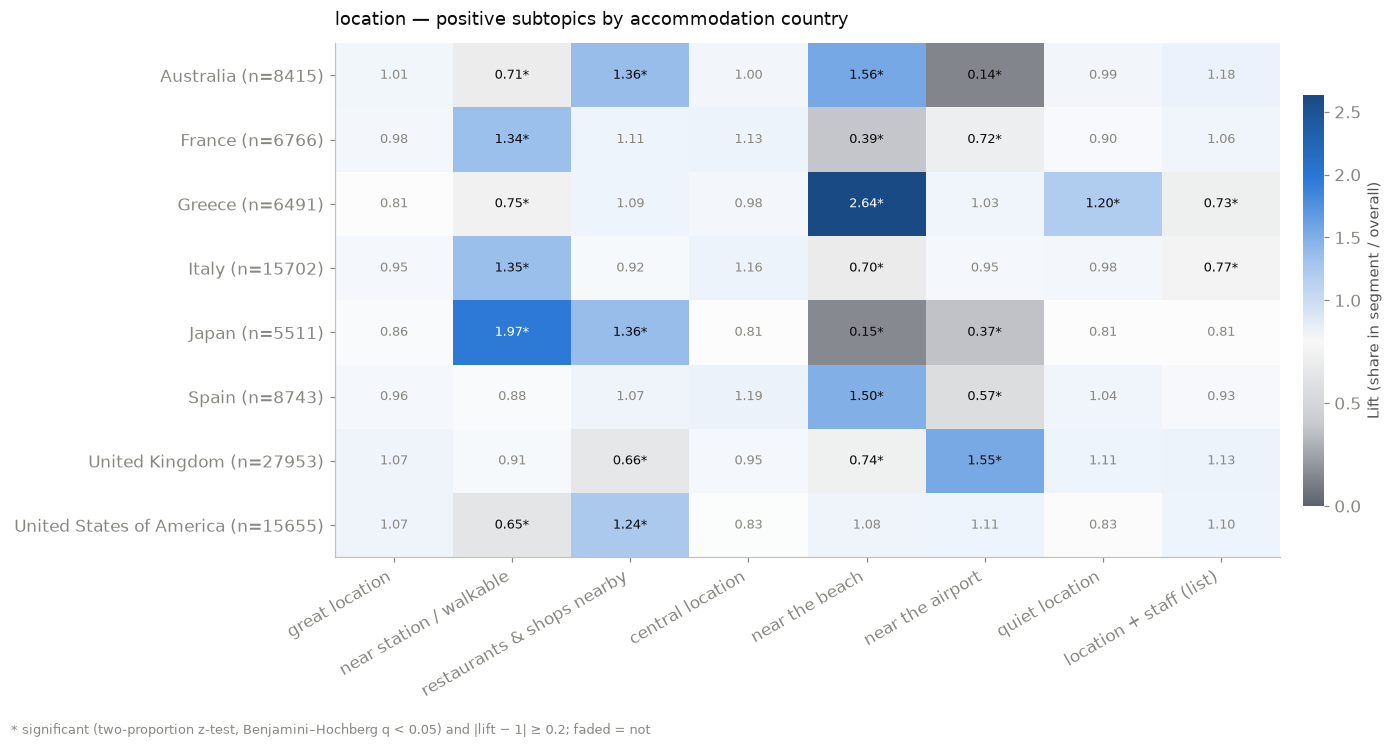

10:40:38 | INFO    | src.evaluation | Table saved: 05_positive_full2_map_staff_by_accommodation_type.csv


,segment,subtopic,lift,count,segment_n,q,significant,notable
11,Apartment,helpful host,4.269,2998,8614,0.0,True,True
19,Bed and Breakfast,helpful host,3.014,2300,9359,0.0,True,True
27,Guest house,helpful host,2.546,2205,10625,0.0,True,True
14,Apartment,extra help & luggage,1.799,942,8614,0.0,True,True
63,Resort,service,1.550,264,5076,0.0,True,True
18,Bed and Breakfast,breakfast & restaurant staff,1.528,1171,9359,0.0,True,True
30,Guest house,extra help & luggage,1.443,932,10625,0.0,True,True
22,Bed and Breakfast,extra help & luggage,1.387,789,9359,0.0,True,True


10:40:39 | INFO    | src.evaluation | Figure saved: 05_positive_full2_map_staff_by_accommodation_type.png


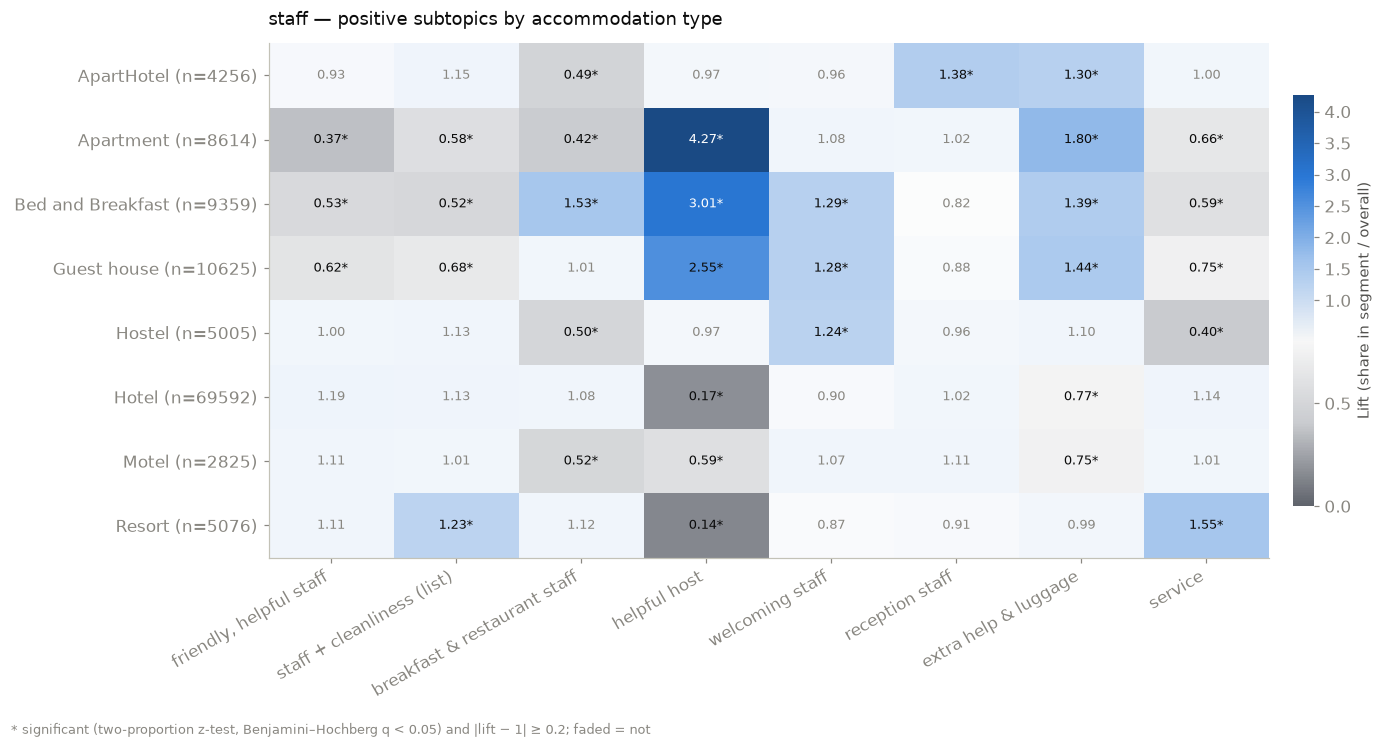

10:40:39 | INFO    | src.evaluation | Table saved: 05_positive_full2_map_staff_by_accommodation_country.csv


,segment,subtopic,lift,count,segment_n,q,significant,notable
22,Greece,extra help & luggage,1.683,478,5066,0.0,True,True
18,Greece,helpful host,1.629,736,5066,0.0,True,True
30,Italy,extra help & luggage,1.629,995,10894,0.0,True,True
26,Italy,helpful host,1.623,1577,10894,0.0,True,True
7,Australia,service,1.429,185,4317,0.0,True,True
51,United Kingdom,breakfast & restaurant staff,1.324,2458,21256,0.0,True,True
41,Thailand,staff + cleanliness (list),1.313,671,3856,0.0,True,True
56,United States of America,"friendly, helpful staff",1.303,6012,10959,0.0,True,True


10:40:40 | INFO    | src.evaluation | Figure saved: 05_positive_full2_map_staff_by_accommodation_country.png


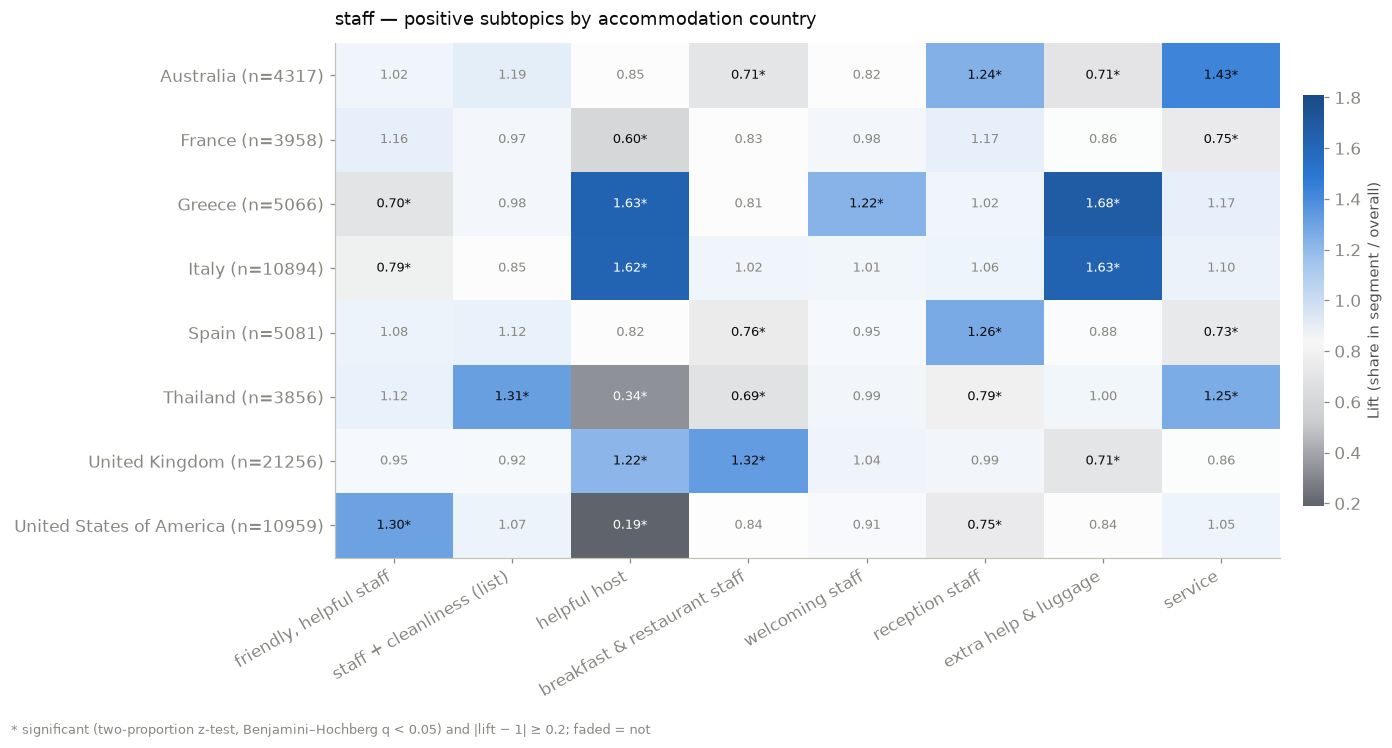

In [13]:
for aspect in MAIN_ASPECTS[:3]:
    for segment in ["accommodation_type", "accommodation_country"]:
        lift = tm.segment_table(assignments, subset, aspect, segment, min_count=50, top_segments=8)
        if lift.empty:
            continue
        long = tm.segment_long_table(lift)
        ev.save_table(long, f"05_{TAG}_map_{aspect}_by_{segment}")
        display(long[long["notable"]].head(8))
        tm.plot_segment_heatmap(lift, f"{aspect.replace('_', ' ')} — {SENTIMENT} subtopics by {segment.replace('_', ' ')}",
                                save_as=f"05_{TAG}_map_{aspect}_by_{segment}", sentiment=SENTIMENT)
        plt.show()

## 6. Manual check

20 random sentences per topic are exported to Excel, and the `fits` column is filled with 1 (fits the topic) or 0. On the completed file the same cell computes the precision per topic.

In [14]:
check_file = PATHS.annotation / f"topic_check_{TAG}.xlsx"
if not check_file.exists():
    top_aspects = MAIN_ASPECTS[:4]
    tm.export_topic_check(topic_table[topic_table["aspect"].isin(top_aspects)],
                          assignments[assignments["aspect"].isin(top_aspects)], subset,
                          filename=check_file.name)
    print("Exported — fill in the 'fits' column, then re-run this cell.")
else:
    precision = tm.evaluate_topic_check(check_file.name)
    precision = (precision.rename(columns={"topic_label": "auto_label"})
                 .merge(topic_table[["aspect", "topic", "label"]], on=["aspect", "topic"], how="left"))
    display(precision); ev.save_table(precision, f"05_{TAG}_topic_precision")

10:40:41 | INFO    | src.topic_modeling | Overall topic precision: 0.927 (800 sentences checked)


,aspect,topic,auto_label,checked,precision,label
0,cleanliness,0,clean / location / cleanliness,20,1.00,very clean (general)
1,cleanliness,1,room / rooms / room clean,20,1.00,clean room
2,cleanliness,2,staff / friendly / friendly staff,20,0.90,clean + friendly staff (list)
3,cleanliness,3,clean comfortable / comfortable / clean,20,1.00,clean & comfortable
4,cleanliness,4,clean / staff / good,20,1.00,clean hotel
5,cleanliness,5,bed / beds / comfortable,20,0.95,clean + comfortable bed
6,cleanliness,6,towels / day / cleaned,20,0.90,daily housekeeping & fresh towels
7,cleanliness,7,breakfast / clean breakfast / good,20,1.00,clean + breakfast (list)
8,cleanliness,8,bathroom / shower / bathroom clean,20,1.00,clean bathroom
9,cleanliness,9,apartment / apartment clean / clean apartment,20,1.00,clean apartment


10:40:41 | INFO    | src.evaluation | Table saved: 05_positive_full2_topic_precision.csv


---
## Summary of outputs

| Output | Content |
|---|---|
| `05_aspect_keyword_vs_model` (table + figure) | 2/a: trained model vs. keyword list on human labels |
| `05_aspect_model_test_report` | precision / recall / F1 per aspect |
| `05_aspect_sentiment_model` | aspect × sentiment with the trained aspects |
| `05_<sentiment>_<version>_removed_non_complaints` | removed non-complaint units ("nothing", "all good") |
| `05_<sentiment>_<version>_granularity_sweep` | comparison of cluster size and merging settings |
| `05_<sentiment>_<version>_subtopics` + `_subtopics_by_aspect.png` | 2/b subtopics per aspect (name + `auto_label` per cluster) |
| `05_<sentiment>_<version>_named_subtopics` | clusters with the same name combined |
| `05_<sentiment>_<version>_subtopic_quality`, `_stability` | coherence, diversity, stability |
| `05_<sentiment>_<version>_map_*` | complaint maps by segment (8 largest subtopics: n, lift, q, significant, substantial) |
| `05_<sentiment>_<version>_topic_precision` | manual check: precision per topic |

`<version>` = `CFG.topic_version` (`full2`). Outputs of earlier versions are kept in `archive/results/`.